# Avance 5 — Modelo final: estrategias de ensamble
### Proyecto Integrador | Equipo 11 — Cloud Copilot
**Integrantes:** Edgar Iván Ramírez, Jorge Muñoz Estrada y Juan Pablo Carvajal  
**Objetivos:** 3.5, evaluar si los ensambles aportan mejoras; y 3.6, evaluar predicciones en datos no vistos.

Estudiamos la clasificación de segmentos de conversaciones técnicas en cinco categorías. Retomamos las familias de clasificadores utilizadas durante el proyecto, ampliamos el corpus sintético y contrastamos modelos individuales con ensambles homogéneos y heterogéneos. Nos interesa el F1-Macro general, pero también evitar decisiones de arquitectura que no se acordaron y reducir la omisión de requisitos en un futuro TDD.

Este experimento aborda la **clasificación de segmentos**. La extracción de información y la redacción del TDD con Gemini se desarrollan como otro componente del proyecto y no intervienen en esta selección.

**Archivos:** `datos_enriquecidos_avance5-v2.csv` y `requirements_avance5.txt`. El conjunto de prueba permanece reservado hasta la selección del modelo.

*(Uso de IA: ChatGPT apoyó la estructura y redacción del notebook. Las cifras y afirmaciones sobre resultados se contrastaron con la ejecución completa y sus salidas.)*

In [1]:
%pip install -r /content/requirements_avance5.txt

## 1. Preparación y revisión de los datos

Trabajamos con cinco categorías: `architecture_decision`, `database_migration`, `next_steps`, `requirement` y `technical_discussion`. Antes de entrenar, eliminamos registros de relleno y textos idénticos y comprobamos que las sesiones no se mezclen entre las particiones.

El conjunto es **sintético**; por ello, los resultados no representan por sí mismos el desempeño sobre reuniones reales.

In [2]:
# Uso de IA: ChatGPT ayudó a estructurar la verificación del entorno y la carga.
# Revisión: comprobación de versiones, hash del archivo y columnas requeridas al ejecutar.
from pathlib import Path
import sys, time, warnings, hashlib
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, scipy
from scipy import stats
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                             classification_report, ConfusionMatrixDisplay, make_scorer,
                             precision_recall_curve, average_precision_score)
from sklearn.exceptions import ConvergenceWarning

# Las importaciones no fijan versiones. Esta comprobación verifica que el entorno
# coincida con el especificado en requirements_avance5.txt.
VERSIONES = {
    'numpy': '2.3.5',
    'pandas': '2.2.3',
    'scipy': '1.17.0',
    'scikit-learn': '1.8.0',
    'matplotlib': '3.10.8',
}
assert sys.version_info[:2] == (3, 13), (
    f'Se necesita Python 3.13; detectado {sys.version.split()[0]}.'
)
for paquete, esperada in VERSIONES.items():
    actual = version(paquete)
    assert actual == esperada, (
        f'{paquete}: instalado {actual}, esperado {esperada}. '
        'Instala requirements_avance5.txt y reinicia el kernel.'
    )

warnings.filterwarnings('ignore', category=ConvergenceWarning)
SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_colwidth', 110)
print('Entorno verificado:', 'Python', sys.version.split()[0],
      '|', ' | '.join(f'{k} {v}' for k,v in VERSIONES.items()))

RUTAS = [Path('datos_enriquecidos_avance5-v2.csv'),
         Path('/content/datos_enriquecidos_avance5-v2.csv'),
         Path('/mnt/data/datos_enriquecidos_avance5-v2.csv')]
ruta = next((r for r in RUTAS if r.exists()), None)
if ruta is None:
    raise FileNotFoundError('Coloca datos_enriquecidos_avance5-v2.csv junto al notebook.')
raw = pd.read_csv(ruta)
requeridas = {'session_id','text_clean','expected_category','dataset_split'}
assert requeridas.issubset(raw.columns), f'Faltan columnas: {requeridas-set(raw.columns)}'
raw['text_clean'] = raw.text_clean.fillna('').astype(str).str.strip()
for columna in ['session_id','expected_category','dataset_split']:
    raw[columna] = raw[columna].astype(str).str.strip()
HASH_DATOS = hashlib.sha256(ruta.read_bytes()).hexdigest()
HASH_ESPERADO = 'b9b4b4e3ccecc0419ec8a81b0aca869924bbcb70d25743419bfe9cdc5a068944'
assert HASH_DATOS == HASH_ESPERADO, 'El archivo CSV no coincide con el corpus verificado.'
print('CSV verificado:', ruta.name, '| registros:',len(raw),'| SHA256:',HASH_DATOS[:16]+'…')

Entorno verificado: Python 3.13.18 | numpy 2.3.5 | pandas 2.2.3 | scipy 1.17.0 | scikit-learn 1.8.0 | matplotlib 3.10.8
CSV verificado: datos_enriquecidos_avance5-v2.csv | registros: 363 | SHA256: b9b4b4e3ccecc041…


In [3]:
# Uso de IA: ChatGPT ayudó a organizar los controles de limpieza.

# Retiramos filas de relleno y textos repetidos antes de entrenar.
es_relleno = raw['text_clean'].str.startswith('Discusión técnica sobre el segmento')
sin_relleno = raw.loc[~es_relleno & raw.text_clean.ne('')].copy()
conflictos = sin_relleno.groupby('text_clean')['expected_category'].nunique().gt(1).sum()
assert conflictos == 0, 'Existen textos iguales con etiquetas distintas; revisar manualmente.'
df = sin_relleno.drop_duplicates('text_clean', keep='first').copy()
CLASES = sorted(df.expected_category.unique())
assert len(CLASES) == 5
assert set(df.dataset_split.unique()) == {'development','validation','test'}
assert df.groupby('session_id').dataset_split.nunique().max() == 1, 'Fuga entre sesiones.'
assert not df.text_clean.duplicated().any()
assert df.groupby('dataset_split').expected_category.nunique().eq(5).all()
resumen_limpieza = pd.DataFrame({
    'Paso':['CSV original','Relleno eliminado','Repeticiones exactas eliminadas','Corpus utilizable'],
    'Filas':[len(raw),int(es_relleno.sum()),len(sin_relleno)-len(df),len(df)]})
display(resumen_limpieza)
display(pd.crosstab(df.dataset_split,df.expected_category,margins=True))
display(df.groupby('dataset_split').agg(segmentos=('text_clean','size'),sesiones=('session_id','nunique')))
print('Distribución por clase:',df.expected_category.value_counts().to_dict())

# Comprobamos cuántas sesiones incluyen las cinco categorías.
print('Sesiones con las cinco clases:',int(df.groupby('session_id').expected_category.nunique().eq(5).sum()),
      'de',df.session_id.nunique())

,Paso,Filas
0,CSV original,363
1,Relleno eliminado,27
2,Repeticiones exactas eliminadas,36
3,Corpus utilizable,300


expected_category,architecture_decision,database_migration,next_steps,requirement,technical_discussion,All
dataset_split,,,,,,
development,35,35,33,33,36,172
test,14,13,10,9,14,60
validation,11,12,17,18,10,68
All,60,60,60,60,60,300


,segmentos,sesiones
dataset_split,,
development,172,34
test,60,9
validation,68,15


Distribución por clase: {'next_steps': 60, 'requirement': 60, 'technical_discussion': 60, 'database_migration': 60, 'architecture_decision': 60}
Sesiones con las cinco clases: 33 de 58


### 1.1 Diseño de evaluación

Utilizamos únicamente `text_clean` como predictor. `session_id` se utiliza para agrupar segmentos durante la validación; no se incorpora como característica del clasificador. Las duraciones, horarios y participantes también se excluyen, porque podrían reflejar patrones de generación del corpus.

- **Desarrollo:** entrenamiento y ajuste de hiperparámetros con validación cruzada `StratifiedGroupKFold` de cuatro folds. Las sesiones se mantienen completas.
- **Validación:** comparación de todos los candidatos y selección mediante una regla definida antes de observar test.
- **Prueba:** evaluación final del modelo seleccionado en sesiones reservadas, después de reentrenarlo con desarrollo y validación.

La métrica principal es **F1-Macro**, calculada con las cinco clases explícitas. Adicionalmente evaluamos accuracy, precisión y recall macro, precisión de `architecture_decision` y recall de `requirement`. La meta de referencia es F1-Macro ≥ 0.70; no equivale a un porcentaje de aciertos.

**Regla de selección:** identificamos el F1-Macro más alto en validación; entre los modelos que queden a un máximo de **0.02 puntos**, priorizamos mayor precisión de decisiones, después recall de requisitos y finalmente menor tiempo de entrenamiento. El margen es un criterio práctico orientado al negocio, **no una prueba de equivalencia estadística**.

In [4]:
# Uso de IA: ChatGPT ayudó a estructurar pipelines y métricas.
# Revisión: etiquetas fijas, ausencia de sesiones compartidas y evaluación solo en validación.
train = df.loc[df.dataset_split=='development'].copy()
val = df.loc[df.dataset_split=='validation'].copy()
test = df.loc[df.dataset_split=='test'].copy()
X_train, y_train, g_train = train.text_clean, train.expected_category, train.session_id
X_val, y_val = val.text_clean, val.expected_category
X_test, y_test = test.text_clean, test.expected_category
CV = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
SCORE = make_scorer(f1_score, average='macro', labels=CLASES, zero_division=0, pos_label=None)
META = 0.70

def revisar_folds(X,y,groups,cv):
    for i,(tr,va) in enumerate(cv.split(X,y,groups),1):
        assert set(groups.iloc[tr]).isdisjoint(set(groups.iloc[va]))
        print(f'Fold {i}: {len(tr)} entrenamiento, {len(va)} validación; clases validación={y.iloc[va].nunique()}')
revisar_folds(X_train,y_train,g_train,CV)

class PasarADenso(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None): return self
    def transform(self, X): return X.toarray() if hasattr(X,'toarray') else np.asarray(X)

def crear_pipeline(modelo, denso=False):
    pasos = [('tfidf',TfidfVectorizer(ngram_range=(1,2), min_df=1,
                                     max_features=4000, sublinear_tf=True))]
    if denso: pasos.append(('denso',PasarADenso()))
    pasos.append(('modelo',modelo))
    return Pipeline(pasos)

def metricas(y_real,y_pred):
    return {'F1-Macro':f1_score(y_real,y_pred,labels=CLASES,average='macro',zero_division=0),
            'Accuracy':accuracy_score(y_real,y_pred),
            'Precisión-Macro':precision_score(y_real,y_pred,labels=CLASES,average='macro',zero_division=0),
            'Recall-Macro':recall_score(y_real,y_pred,labels=CLASES,average='macro',zero_division=0),
            'Precisión decisiones':precision_score(y_real,y_pred,labels=['architecture_decision'],average='macro',zero_division=0),
            'Recall requisitos':recall_score(y_real,y_pred,labels=['requirement'],average='macro',zero_division=0)}

resultados = []  # métricas de validación para comparar candidatos
entrenados = {}
constructores = {}  # reconstrucción del modelo seleccionado

def guardar(nombre, modelo, tiempo_fit, tiempo_busqueda=0, familia='Individual'):
    y_pred = modelo.predict(X_val)
    t0=time.perf_counter(); modelo.predict(X_val); t_pred=time.perf_counter()-t0
    fila={'Modelo':nombre,'Familia':familia,'Entrenamiento (s)':tiempo_fit,
          'Búsqueda (s)':tiempo_busqueda,f'Predicción {len(X_val)} seg. (ms)':t_pred*1000}
    fila.update(metricas(y_val,y_pred))
    resultados.append(fila)
    entrenados[nombre]=modelo
    print(f'{nombre:<27} F1-Macro validación={fila["F1-Macro"]:.3f}, precisión decisiones={fila["Precisión decisiones"]:.3f}')

def ajustar_y_registrar(nombre,modelo,familia='Individual'):
    t0=time.perf_counter(); modelo.fit(X_train,y_train)
    guardar(nombre,modelo,time.perf_counter()-t0,familia=familia)
    constructores[nombre] = lambda x, plantilla=clone(modelo): clone(plantilla).fit(x.text_clean, x.expected_category)
    return modelo

Fold 1: 126 entrenamiento, 46 validación; clases validación=5
Fold 2: 128 entrenamiento, 44 validación; clases validación=5
Fold 3: 132 entrenamiento, 40 validación; clases validación=5
Fold 4: 130 entrenamiento, 42 validación; clases validación=5


## 2. Clasificadores individuales como referencia

Entrenamos seis familias individuales de clasificación —Regresión Logística, Gaussian Naive Bayes, SVC, Árbol de Decisión, KNN y MLP— con el mismo corpus y la misma representación de texto. Agregamos un **Random Forest sin ajuste**, que es un ensamble homogéneo, para evaluar posteriormente el efecto de ajustar sus hiperparámetros.

Estas métricas corresponden al corpus y a las particiones de este experimento; no comparamos directamente puntuaciones obtenidas sobre otros conjuntos de observaciones.

In [5]:
# Uso de IA: ChatGPT ayudó a documentar las configuraciones iniciales.
# Revisión: cada pipeline se ajustó en desarrollo y se evaluó sobre validación.
# LR, GaussianNB y SVC también serán los componentes de los ensambles heterogéneos.
individuales = {
 'Regresión Logística':crear_pipeline(LogisticRegression(C=1.0,max_iter=1500,random_state=SEED)),
 'Naive Bayes (Gauss)':crear_pipeline(GaussianNB(var_smoothing=1e-8),denso=True),
 'SVC':crear_pipeline(SVC(kernel='linear',C=1.0,probability=True,random_state=SEED)),
 'Árbol de Decisión':crear_pipeline(DecisionTreeClassifier(max_depth=12,random_state=SEED)),
 'KNN':crear_pipeline(KNeighborsClassifier(n_neighbors=5,metric='cosine')),
 'MLP':crear_pipeline(MLPClassifier(hidden_layer_sizes=(40,),alpha=0.01,max_iter=300,
                                    early_stopping=False,random_state=SEED)),
 'Random Forest sin ajuste':crear_pipeline(RandomForestClassifier(n_estimators=120,
                                                    random_state=SEED,n_jobs=1))
}
for nombre,pipe in individuales.items():
    ajustar_y_registrar(nombre,pipe)

Regresión Logística         F1-Macro validación=0.775, precisión decisiones=0.467
Naive Bayes (Gauss)         F1-Macro validación=0.676, precisión decisiones=0.417
SVC                         F1-Macro validación=0.793, precisión decisiones=0.467
Árbol de Decisión           F1-Macro validación=0.468, precisión decisiones=0.500
KNN                         F1-Macro validación=0.708, precisión decisiones=0.438
MLP                         F1-Macro validación=0.726, precisión decisiones=0.417
Random Forest sin ajuste    F1-Macro validación=0.697, precisión decisiones=0.556


## 3. Ensambles homogéneos

Comparamos Random Forest, Extra Trees y AdaBoost. Los dos primeros combinan múltiples árboles con diferentes mecanismos de aleatoriedad; AdaBoost construye estimadores de forma secuencial y ajusta la importancia de los ejemplos.

Usamos `RandomizedSearchCV` para explorar ocho configuraciones de Random Forest y ocho de AdaBoost, evaluadas mediante cuatro folds agrupados por sesión. Para Extra Trees fijamos una configuración de referencia. Los tiempos de búsqueda y de entrenamiento de un solo modelo se reportan por separado.

In [6]:
# Uso de IA: ChatGPT ayudó a estructurar el procedimiento de búsqueda.
# Revisión: se contrastaron hiperparámetros, folds, mejores puntuaciones y tiempos.
def buscar_y_registrar(nombre,base,espacio,n_iter):
    busqueda=RandomizedSearchCV(
        base, param_distributions=espacio,n_iter=n_iter,
        scoring=SCORE,cv=CV,random_state=SEED,n_jobs=1,refit=True,error_score='raise')
    t0=time.perf_counter(); busqueda.fit(X_train,y_train,groups=g_train)
    t_busqueda=time.perf_counter()-t0
    # Tiempo comparable: entrenamiento único de la configuración ganadora.
    t0=time.perf_counter(); modelo=clone(busqueda.best_estimator_).fit(X_train,y_train)
    t_fit=time.perf_counter()-t0
    guardar(nombre,modelo,t_fit,tiempo_busqueda=t_busqueda,familia='Ensamble homogéneo')
    constructores[nombre]=lambda x, plantilla=clone(busqueda.best_estimator_): clone(plantilla).fit(x.text_clean,x.expected_category)
    print('  Mejor F1 de CV interna:',round(busqueda.best_score_,3))
    print('  Hiperparámetros:',{k.replace('modelo__',''):v for k,v in busqueda.best_params_.items()})
    return busqueda

busqueda_rf = buscar_y_registrar('Random Forest ajustado',
    crear_pipeline(RandomForestClassifier(random_state=SEED,n_jobs=1)),
    {'modelo__n_estimators':[80,120,180],
     'modelo__max_depth':[None,12,25],
     'modelo__min_samples_leaf':[1,2,4],
     'modelo__max_features':['sqrt',0.7],
     'modelo__class_weight':[None,'balanced']},n_iter=8)

busqueda_ada = buscar_y_registrar('AdaBoost ajustado',
    crear_pipeline(AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=SEED),random_state=SEED)),
    {'modelo__n_estimators':[40,80,120],
     'modelo__learning_rate':[0.05,0.2,0.7,1.0],
     'modelo__estimator__max_depth':[1,2,3],
     'modelo__estimator__min_samples_leaf':[1,2]},n_iter=8)

ajustar_y_registrar('Extra Trees',crear_pipeline(ExtraTreesClassifier(n_estimators=120,
                      min_samples_leaf=2,random_state=SEED,n_jobs=1)),familia='Ensamble homogéneo')

Random Forest ajustado      F1-Macro validación=0.768, precisión decisiones=0.583
  Mejor F1 de CV interna: 0.632
  Hiperparámetros: {'n_estimators': 120, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None, 'class_weight': None}
AdaBoost ajustado           F1-Macro validación=0.569, precisión decisiones=0.333
  Mejor F1 de CV interna: 0.552
  Hiperparámetros: {'n_estimators': 80, 'learning_rate': 1.0, 'estimator__min_samples_leaf': 1, 'estimator__max_depth': 2}
Extra Trees                 F1-Macro validación=0.747, precisión decisiones=0.600


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('tfidf', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None


## 4. Ensambles heterogéneos: Soft Voting y Stacking

Combinamos Regresión Logística, Naive Bayes y SVC porque representan mecanismos de clasificación distintos y permiten estudiar si esa diversidad mejora las predicciones.

**Soft Voting** calcula un promedio ponderado de las probabilidades de los tres modelos. Comparamos seis combinaciones de pesos usando cuatro folds agrupados por sesión en desarrollo.

**Stacking** aprende a combinar las probabilidades mediante una Regresión Logística de segundo nivel. Las 15 características que recibe el metamodelo se obtienen mediante predicciones *out-of-fold* (tres modelos por cinco clases), para evitar entrenarlo con predicciones de modelos base que ya vieron esos segmentos.

In [7]:
# Uso de IA: ChatGPT ayudó a preparar la búsqueda de pesos.
# Revisión: seis combinaciones evaluadas con agrupación por sesión y pesos impresos.
def bases_heterogeneas():
    return [
      ('lr',clone(individuales['Regresión Logística'])),
      ('nb',clone(individuales['Naive Bayes (Gauss)'])),
      ('svc',clone(individuales['SVC']))]

voting = VotingClassifier(estimators=bases_heterogeneas(),voting='soft',n_jobs=1)
# Los pesos se eligen con CV agrupada sobre desarrollo. Validación no participa.
pesos = [(1,1,1),(2,1,1),(1,2,1),(1,1,2),(2,2,1),(2,1,2)]
q_vot = RandomizedSearchCV(voting,{'weights':pesos},n_iter=len(pesos),cv=CV,
                           scoring=SCORE,refit=True,random_state=SEED,n_jobs=1)
t0=time.perf_counter();q_vot.fit(X_train,y_train,groups=g_train);t_busqueda=time.perf_counter()-t0
t0=time.perf_counter();mod_vot=clone(q_vot.best_estimator_).fit(X_train,y_train);t_fit=time.perf_counter()-t0
guardar('Soft Voting',mod_vot,t_fit,t_busqueda,familia='Ensamble heterogéneo')
constructores['Soft Voting']=lambda x: clone(q_vot.best_estimator_).fit(x.text_clean,x.expected_category)
print('Pesos elegidos (LR, NB, SVC):',q_vot.best_params_['weights'])

Soft Voting                 F1-Macro validación=0.745, precisión decisiones=0.500
Pesos elegidos (LR, NB, SVC): (1, 1, 2)


In [8]:
# Uso de IA: ChatGPT ayudó a implementar el Stacking con predicciones OOF.
# Revisión: se verificó que cada segmento se predice una vez y no comparte sesión con el entrenamiento del fold.
# Stacking explícito: usamos 4 folds agrupados por sesión para construir las
# probabilidades out-of-fold que verá el metamodelo, no probabilidades de entrenamiento.
class StackingPorSesion:
    def __init__(self,n_splits=4,seed=42):
        self.n_splits=n_splits
        self.seed=seed
    def fit(self,X,y,groups):
        X=pd.Series(X).reset_index(drop=True).astype(str)
        y=pd.Series(y).reset_index(drop=True)
        groups=pd.Series(groups).reset_index(drop=True)
        self.classes_=np.sort(y.unique())
        cv=StratifiedGroupKFold(n_splits=self.n_splits,shuffle=True,random_state=self.seed)
        prototipos=bases_heterogeneas()
        meta_features=[]
        for nombre,modelo in prototipos:
            oof=np.zeros((len(X),len(self.classes_)))
            cobertura=np.zeros(len(X),dtype=int)
            for tr,va in cv.split(X,y,groups):
                assert set(groups.iloc[tr]).isdisjoint(set(groups.iloc[va]))
                fold=clone(modelo).fit(X.iloc[tr],y.iloc[tr])
                prob=fold.predict_proba(X.iloc[va])
                ind=[list(self.classes_).index(cl) for cl in fold.classes_]
                oof[np.ix_(va,ind)]=prob
                cobertura[va]+=1
            assert np.all(cobertura==1)
            meta_features.append(oof)
        self.meta_=LogisticRegression(C=1.0,max_iter=1500,random_state=self.seed)
        self.meta_.fit(np.hstack(meta_features),y)
        self.bases_=[(nombre,clone(mod).fit(X,y)) for nombre,mod in prototipos]
        return self
    def transformar(self,X):
        X=pd.Series(X).astype(str)
        return np.hstack([m.predict_proba(X)[:,[list(m.classes_).index(c) for c in self.classes_]]
                          for _,m in self.bases_])
    def predict_proba(self,X):
        return self.meta_.predict_proba(self.transformar(X))
    def predict(self,X):
        return self.meta_.predict(self.transformar(X))

modelo_stack=StackingPorSesion()
t0=time.perf_counter();modelo_stack.fit(X_train,y_train,g_train);t_fit=time.perf_counter()-t0
guardar('Stacking agrupado',modelo_stack,t_fit,familia='Ensamble heterogéneo')
constructores['Stacking agrupado']=lambda x: StackingPorSesion().fit(x.text_clean,x.expected_category,x.session_id)

Stacking agrupado           F1-Macro validación=0.774, precisión decisiones=0.500


## 5. Comparación y selección

Ordenamos los modelos por F1-Macro en validación e incluimos métricas secundarias y tiempos. El tiempo de búsqueda incluye los ajustes exploratorios, mientras que el de entrenamiento corresponde a una ejecución de la configuración elegida.

Aplicamos la regla previamente definida sobre los resultados de **validación**; el conjunto de prueba no participa en esta decisión.

,Modelo,Familia,F1-Macro,Accuracy,Precisión-Macro,Recall-Macro,Precisión decisiones,Recall requisitos,Entrenamiento (s),Búsqueda (s),Predicción 68 seg. (ms)
0,SVC,Individual,0.793,0.794,0.803,0.805,0.467,0.667,0.113,0.000,7.936
1,Regresión Logística,Individual,0.775,0.779,0.788,0.785,0.467,0.667,0.130,0.000,12.993
2,Stacking agrupado,Ensamble heterogéneo,0.774,0.794,0.772,0.777,0.500,0.889,1.207,0.000,17.297
3,Random Forest ajustado,Ensamble homogéneo,0.768,0.779,0.779,0.781,0.583,0.611,0.240,34.472,14.623
4,Extra Trees,Ensamble homogéneo,0.747,0.765,0.749,0.757,0.600,0.722,0.343,0.000,25.515
5,Soft Voting,Ensamble heterogéneo,0.745,0.765,0.742,0.755,0.500,0.778,0.344,7.344,16.929
6,MLP,Individual,0.726,0.750,0.725,0.731,0.417,0.778,5.180,0.000,9.376
7,KNN,Individual,0.708,0.706,0.730,0.723,0.438,0.556,0.019,0.000,8.659
8,Random Forest sin ajuste,Individual,0.697,0.721,0.710,0.707,0.556,0.667,0.833,0.000,38.922
9,Naive Bayes (Gauss),Individual,0.676,0.691,0.682,0.683,0.417,0.722,0.047,0.000,11.071


Mejor F1-Macro: 0.793 | Finalistas dentro del margen de 0.02: ['Stacking agrupado', 'SVC', 'Regresión Logística']
SELECCIÓN ANTES DE TEST: Stacking agrupado
Criterio: F1-Macro dentro de 0.02 del máximo; después precisión de decisiones, recall de requisitos y tiempo.
Cumple meta 0.70 en validación: True


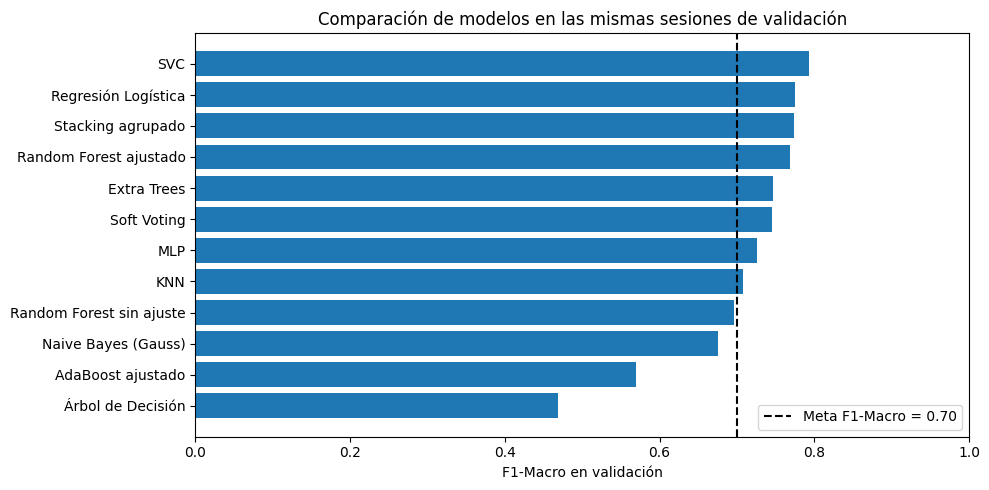

In [9]:
# Uso de IA: ChatGPT ayudó a estructurar la tabla y la regla de selección.
# Revisión: se contrastó el modelo seleccionado con las cifras de validación.
tabla=pd.DataFrame(resultados).sort_values('F1-Macro',ascending=False).reset_index(drop=True)
cols=['Modelo','Familia','F1-Macro','Accuracy','Precisión-Macro','Recall-Macro',
      'Precisión decisiones','Recall requisitos','Entrenamiento (s)','Búsqueda (s)',
      f'Predicción {len(X_val)} seg. (ms)']
display(tabla[cols].round(3))

mejor_f1=tabla.iloc[0]['F1-Macro']
candidatos=tabla.loc[tabla['F1-Macro'] >= mejor_f1-0.02-1e-12].copy()
candidatos=candidatos.sort_values(['Precisión decisiones','Recall requisitos','Entrenamiento (s)'],
                                   ascending=[False,False,True])
nombre_final=candidatos.iloc[0]['Modelo']
print('Mejor F1-Macro:',round(mejor_f1,3),'| Finalistas dentro del margen de 0.02:',
      candidatos.Modelo.tolist())
print('SELECCIÓN ANTES DE TEST:',nombre_final)
print('Criterio: F1-Macro dentro de 0.02 del máximo; después precisión de decisiones, recall de requisitos y tiempo.')
print('Cumple meta 0.70 en validación:', bool(tabla.set_index('Modelo').loc[nombre_final,'F1-Macro']>=META))

fig, ax=plt.subplots(figsize=(10,5))
orden=tabla.sort_values('F1-Macro',ascending=True)
ax.barh(orden.Modelo,orden['F1-Macro'])
ax.axvline(META,ls='--',color='black',label='Meta F1-Macro = 0.70')
ax.set(xlim=(0,1),xlabel='F1-Macro en validación',title='Comparación de modelos en las mismas sesiones de validación')
ax.legend(loc='lower right');plt.tight_layout();plt.show()

In [10]:
# Uso de IA: ChatGPT ayudó a redactar un análisis dependiente de los resultados.
# Revisión: los indicadores se toman directamente de la tabla calculada.
seleccion = tabla.set_index('Modelo').loc[nombre_final]
mejor_individual_val = tabla.loc[tabla['Familia']=='Individual'].iloc[0]
mejor_homogeneo = tabla.loc[tabla['Familia']=='Ensamble homogéneo'].iloc[0]
mejor_heterogeneo = tabla.loc[tabla['Familia']=='Ensamble heterogéneo'].iloc[0]

def explicar_seleccion():
    print('ANÁLISIS DE VALIDACIÓN')
    print(f'Mayor F1-Macro global: {tabla.iloc[0]["Modelo"]} ({mejor_f1:.3f}).')
    print(f'Mejor individual: {mejor_individual_val["Modelo"]} ({mejor_individual_val["F1-Macro"]:.3f}).')
    print(f'Mejor ensamble homogéneo: {mejor_homogeneo["Modelo"]} ({mejor_homogeneo["F1-Macro"]:.3f}).')
    print(f'Mejor ensamble heterogéneo: {mejor_heterogeneo["Modelo"]} ({mejor_heterogeneo["F1-Macro"]:.3f}).')
    print(f'Modelo seleccionado: {nombre_final}, F1-Macro={seleccion["F1-Macro"]:.3f}, '
          f'precisión decisiones={seleccion["Precisión decisiones"]:.3f}, '
          f'recall requisitos={seleccion["Recall requisitos"]:.3f}.')
    diferencia = mejor_f1-seleccion['F1-Macro']
    print(f'Diferencia frente al mejor F1: {diferencia:.4f} puntos (margen permitido: 0.020).')
    if mejor_heterogeneo['F1-Macro'] > mejor_individual_val['F1-Macro']:
        print('El mejor ensamble heterogéneo superó al mejor individual en esta validación.')
    else:
        print('El mejor ensamble heterogéneo no superó al mejor individual en esta validación.')
    print('La regla de selección prioriza errores relevantes para el TDD; esto no demuestra superioridad estadística.')

explicar_seleccion()

ANÁLISIS DE VALIDACIÓN
Mayor F1-Macro global: SVC (0.793).
Mejor individual: SVC (0.793).
Mejor ensamble homogéneo: Random Forest ajustado (0.768).
Mejor ensamble heterogéneo: Stacking agrupado (0.774).
Modelo seleccionado: Stacking agrupado, F1-Macro=0.774, precisión decisiones=0.500, recall requisitos=0.889.
Diferencia frente al mejor F1: 0.0197 puntos (margen permitido: 0.020).
El mejor ensamble heterogéneo no superó al mejor individual en esta validación.
La regla de selección prioriza errores relevantes para el TDD; esto no demuestra superioridad estadística.


### 5.1 Comprobación estadística exploratoria

Comparamos SVC y Stacking con cinco folds agrupados por sesión **sobre desarrollo**, sin utilizar el conjunto de prueba. Calculamos en cada fold la diferencia de F1-Macro entre ambos y aplicamos una prueba t corregida para considerar, de forma aproximada, la dependencia entre los resultados de validación cruzada.

Se trata de un análisis complementario: los folds comparten observaciones de entrenamiento, hay pocos grupos y la agrupación por sesión hace que la aproximación tenga limitaciones. Un valor p mayor que 0.05 **no demuestra equivalencia ni empate**, y la prueba **no sustituye la regla de selección predefinida**.

In [11]:
# Uso de IA: ChatGPT ayudó a estructurar la prueba t corregida.
# Revisión: cálculo con diferencias pareadas, proporciones reales de folds y cinco clases fijas.
def t_corregida_cv(diferencias, razones_val_ent):
    d = np.asarray(diferencias, dtype=float)
    k = len(d)
    assert k >= 3
    var = d.var(ddof=1)
    correccion = 1/k + np.mean(razones_val_ent)
    if np.isclose(var, 0):
        return np.nan, np.nan
    t = d.mean()/np.sqrt(correccion*var)
    p = 2*stats.t.sf(abs(t), df=k-1)
    return t, p

cv_estadistica = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
f1_svc, f1_stacking, razones = [], [], []
for tr, va in cv_estadistica.split(X_train, y_train, g_train):
    assert set(g_train.iloc[tr]).isdisjoint(set(g_train.iloc[va]))
    x_tr, y_tr, g_tr = X_train.iloc[tr], y_train.iloc[tr], g_train.iloc[tr]
    x_va, y_va = X_train.iloc[va], y_train.iloc[va]
    clf_svc = clone(individuales['SVC']).fit(x_tr,y_tr)
    clf_stack = StackingPorSesion(n_splits=4,seed=SEED).fit(x_tr,y_tr,g_tr)
    f1_svc.append(f1_score(y_va,clf_svc.predict(x_va),labels=CLASES,average='macro',zero_division=0))
    f1_stacking.append(f1_score(y_va,clf_stack.predict(x_va),labels=CLASES,average='macro',zero_division=0))
    razones.append(len(va)/len(tr))

diferencias_cv = np.array(f1_stacking)-np.array(f1_svc)
t_estadistico, p_valor = t_corregida_cv(diferencias_cv, razones)
resumen_estadistico = pd.DataFrame({
    'Fold':np.arange(1,len(f1_svc)+1),'SVC':f1_svc,
    'Stacking':f1_stacking,'Diferencia (Stacking−SVC)':diferencias_cv
})
display(resumen_estadistico.round(3))
print('F1-Macro medio SVC:',round(np.mean(f1_svc),3))
print('F1-Macro medio Stacking:',round(np.mean(f1_stacking),3))
print('Diferencia media:',round(diferencias_cv.mean(),3))
print('t corregida:',round(t_estadistico,3),'| p:',round(p_valor,3))
if np.isnan(p_valor):
    print('Varianza prácticamente nula: no es posible interpretar esta prueba.')
elif p_valor < 0.05:
    print('La prueba detectó una diferencia bajo sus supuestos; su dirección debe interpretarse con los resultados.')
else:
    print('No encontramos evidencia suficiente de diferencia con esta prueba; esto NO implica equivalencia.')
print('La selección sigue siendo:', nombre_final, '(definida mediante validación y la regla de negocio).')

,Fold,SVC,Stacking,Diferencia (Stacking−SVC)
0,1,0.895,0.823,-0.072
1,2,0.712,0.712,-0.000
2,3,0.607,0.681,0.074
3,4,0.736,0.661,-0.075
4,5,0.798,0.731,-0.066


F1-Macro medio SVC: 0.749
F1-Macro medio Stacking: 0.722
Diferencia media: -0.028
t corregida: -0.643 | p: 0.555
No encontramos evidencia suficiente de diferencia con esta prueba; esto NO implica equivalencia.
La selección sigue siendo: Stacking agrupado (definida mediante validación y la regla de negocio).


### 5.2 Características relevantes en Random Forest

Inspeccionamos las quince características de TF-IDF con mayor importancia según el criterio de disminución de impureza del Random Forest ajustado. Es un análisis **de ese ensamble de árboles**; no representa directamente las razones de SVC o Stacking.

Esta medida no demuestra causalidad ni comprensión semántica. Nos ayuda a detectar si aparecen palabras o expresiones recurrentes que ameriten revisión del corpus sintético.

,Característica,Importancia
0,must,0.04174
1,the,0.03525
2,we,0.03040
3,to,0.02353
4,for,0.01933
5,for the,0.01646
6,legacy,0.01486
7,will,0.01425
8,database,0.01283
9,if,0.01270


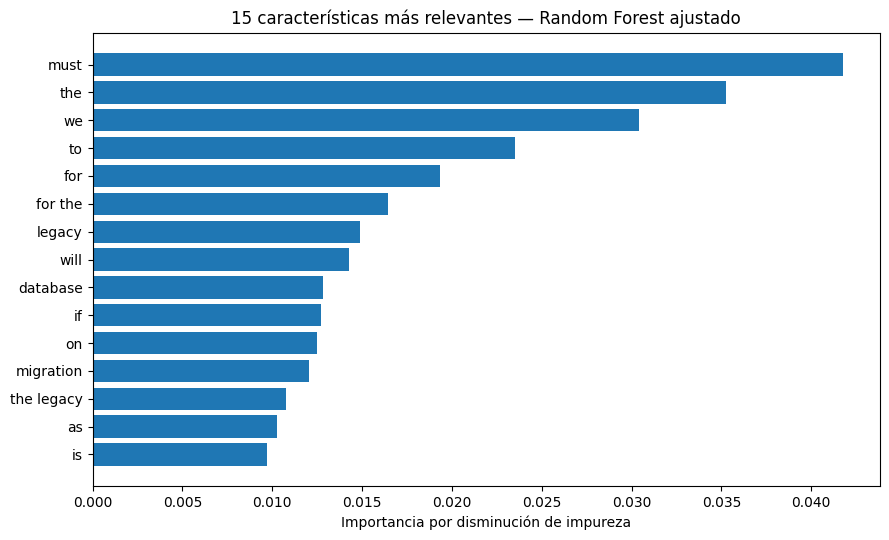

Lectura: aparecen entre las principales características: must, the, we, to, for, for the.
Son asociaciones léxicas del corpus sintético, no una prueba de comprensión del contexto.


In [12]:
# Uso de IA: ChatGPT ayudó a organizar la visualización de importancias.
# Revisión: correspondencia entre vocabulario TF-IDF e importancias del Random Forest entrenado.
rf_pipeline = busqueda_rf.best_estimator_
terminos = rf_pipeline.named_steps['tfidf'].get_feature_names_out()
importancias = rf_pipeline.named_steps['modelo'].feature_importances_
assert len(terminos) == len(importancias)
indices_top = np.argsort(importancias)[-15:][::-1]
tabla_importancia = pd.DataFrame({
    'Característica':terminos[indices_top],
    'Importancia':importancias[indices_top]
})
display(tabla_importancia.round(5))
fig, ax = plt.subplots(figsize=(9,5.5))
orden = tabla_importancia.iloc[::-1]
ax.barh(orden['Característica'],orden['Importancia'])
ax.set(xlabel='Importancia por disminución de impureza',
       title='15 características más relevantes — Random Forest ajustado')
plt.tight_layout()
plt.show()
print('Lectura: aparecen entre las principales características:',
      ', '.join(tabla_importancia['Característica'].head(6).tolist())+'.')
print('Son asociaciones léxicas del corpus sintético, no una prueba de comprensión del contexto.')

## 6. Evaluación final en sesiones reservadas

Después de seleccionar el modelo con validación, lo reentrenamos con las 240 observaciones de **desarrollo + validación** y evaluamos sus predicciones sobre 60 segmentos de nueve sesiones de prueba. Este conjunto no participa en la búsqueda, en la selección ni en la prueba estadística exploratoria.

Mostramos matriz de confusión, precisión y recall por clase, curva precisión–recall para decisiones de arquitectura y ejemplos de errores. Las referencias adicionales se presentan solo de forma descriptiva; no se cambia el modelo seleccionado según su resultado en prueba.

In [13]:
# Uso de IA: ChatGPT ayudó a estructurar la evaluación final.
# Revisión: se verificó separación de sesiones, reporte por categoría y ausencia de selección basada en test.
dev_total=df.loc[df.dataset_split.isin(['development','validation'])].copy()
assert set(dev_total.session_id).isdisjoint(set(test.session_id))
t0=time.perf_counter()
modelo_final=constructores[nombre_final](dev_total)
tiempo_refit=time.perf_counter()-t0
pred_test=modelo_final.predict(X_test)
metrics_test=metricas(y_test,pred_test)
print('Modelo seleccionado:',nombre_final)
print('Tiempo de entrenamiento final (240 seg.):',round(tiempo_refit,3),'s')
print('Métricas test:',{k:round(v,3) for k,v in metrics_test.items()})
print('Meta F1-Macro en prueba alcanzada:',metrics_test['F1-Macro']>=META)
print('\nReporte por clase (60 segmentos nuevos):')
print(classification_report(y_test,pred_test,labels=CLASES,zero_division=0,digits=3))

# Referencia adicional únicamente si es distinta del modelo elegido.
mejor_individual=tabla[tabla.Familia=='Individual'].iloc[0].Modelo
if nombre_final != mejor_individual:
    modelo_individual=constructores[mejor_individual](dev_total)
    pred_individual=modelo_individual.predict(X_test)
    comp=pd.DataFrame([{'Modelo':nombre_final,'F1-Macro test':metrics_test['F1-Macro'],
                        'Accuracy test':metrics_test['Accuracy']},
                       {'Modelo':mejor_individual+' (referencia)',
                        'F1-Macro test':f1_score(y_test,pred_individual,labels=CLASES,average='macro',zero_division=0),
                        'Accuracy test':accuracy_score(y_test,pred_individual)}])
    print('Referencia descriptiva en test; no intervino en la selección:')
    display(comp.round(3))
else:
    print('El mejor individual ya es el modelo final; se omite una comparación redundante.')

Modelo seleccionado: Stacking agrupado
Tiempo de entrenamiento final (240 seg.): 2.563 s
Métricas test: {'F1-Macro': 0.814, 'Accuracy': 0.817, 'Precisión-Macro': 0.814, 'Recall-Macro': 0.816, 'Precisión decisiones': 0.733, 'Recall requisitos': 0.778}
Meta F1-Macro en prueba alcanzada: True

Reporte por clase (60 segmentos nuevos):
                       precision    recall  f1-score   support

architecture_decision      0.733     0.786     0.759        14
   database_migration      1.000     1.000     1.000        13
           next_steps      0.727     0.800     0.762        10
          requirement      0.778     0.778     0.778         9
 technical_discussion      0.833     0.714     0.769        14

             accuracy                          0.817        60
            macro avg      0.814     0.816     0.814        60
         weighted avg      0.820     0.817     0.817        60

Referencia descriptiva en test; no intervino en la selección:


,Modelo,F1-Macro test,Accuracy test
0,Stacking agrupado,0.814,0.817
1,SVC (referencia),0.781,0.783


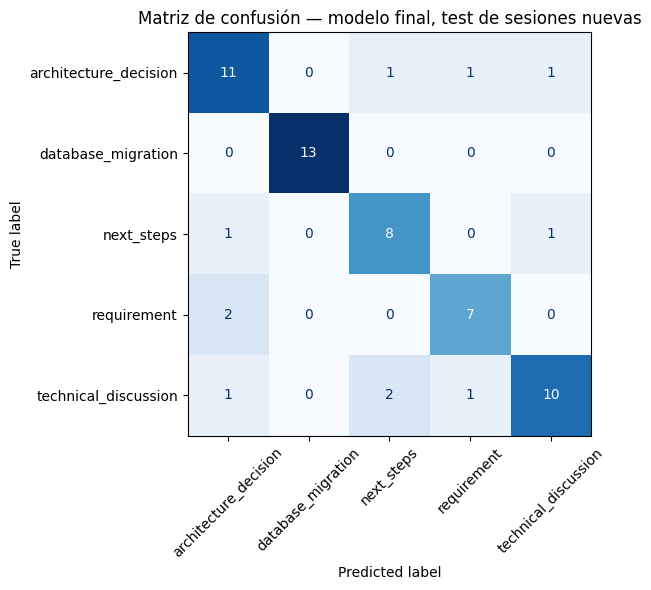

,precision,recall,f1-score,support
architecture_decision,0.733,0.786,0.759,14.0
database_migration,1.000,1.000,1.000,13.0
next_steps,0.727,0.800,0.762,10.0
requirement,0.778,0.778,0.778,9.0
technical_discussion,0.833,0.714,0.769,14.0


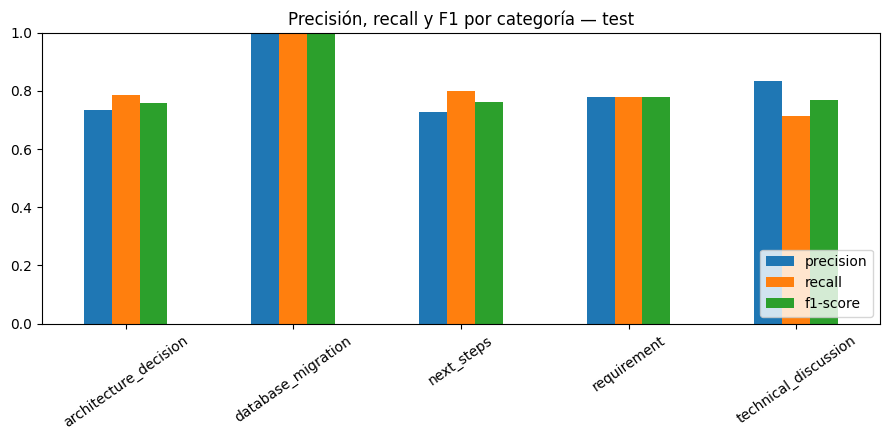

In [14]:
# Uso de IA: ChatGPT apoyó la visualización de matriz de confusión y métricas.
# Revisión: los gráficos se generan directamente a partir de las predicciones de test.
fig, ax=plt.subplots(figsize=(8,6))
ConfusionMatrixDisplay.from_predictions(y_test,pred_test,labels=CLASES,xticks_rotation=45,
                                        cmap='Blues',ax=ax,colorbar=False)
ax.set_title('Matriz de confusión — modelo final, test de sesiones nuevas')
plt.tight_layout();plt.show()

report=classification_report(y_test,pred_test,labels=CLASES,zero_division=0,output_dict=True)
por_clase=pd.DataFrame(report).T.loc[CLASES,['precision','recall','f1-score','support']]
display(por_clase.round(3))
fig,ax=plt.subplots(figsize=(9,4.5))
por_clase[['precision','recall','f1-score']].plot(kind='bar',ax=ax)
ax.set(title='Precisión, recall y F1 por categoría — test',ylim=(0,1),xlabel='')
ax.tick_params(axis='x',rotation=35);ax.legend(loc='lower right')
plt.tight_layout();plt.show()

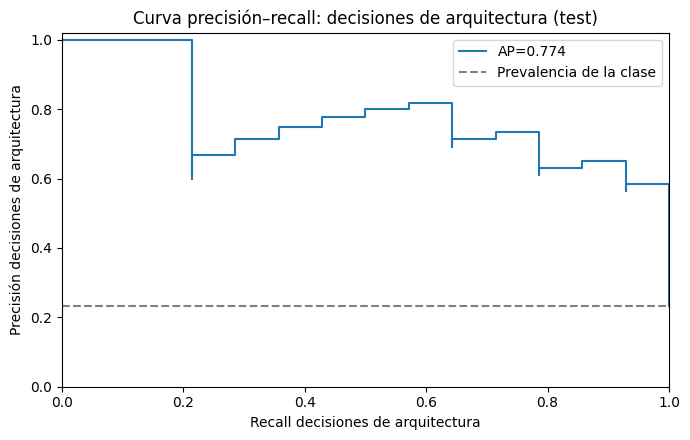

Segmentos mal clasificados: 11 de 60


,session_id,text_clean,expected_category,prediccion
303,S55_DISCOVERY,Corporate single sign-on via SAML 2.0 with multi-factor authentication is mandatory for all user logins.,requirement,architecture_decision
313,S56_ARCHITECTURE,I will update the architecture diagram in Lucidchart to reflect the Private Service Connect changes we agr...,next_steps,architecture_decision
321,S57_SECURITY,We were comparing the throughput of standard persistent disks against balanced SSDs for the staging nodes.,technical_discussion,next_steps
324,S58_IMPLEMENTATION,VPC Service Controls establish a strict security perimeter around the sensitive financial datasets.,architecture_decision,requirement
333,S59_REVIEW,Failed transcript jobs route to a Pub/Sub dead-letter topic paired with an exponential backoff retry policy.,architecture_decision,technical_discussion
339,S60_HANDOVER,What are the pros and cons of using regional versus multi-regional buckets for intermediate staging files?,technical_discussion,requirement
343,S61_DISCOVERY,"One option on the table is a Shared VPC, though the networking team raised questions about subnet IP exhau...",technical_discussion,next_steps
347,S61_DISCOVERY,Information security policy prohibits outbound network traffic unless it passes through the inspected ente...,requirement,architecture_decision
348,S61_DISCOVERY,All compute and storage resources are restricted to the southamerica-east1 region for compliance.,architecture_decision,next_steps
349,S61_DISCOVERY,Let's assign an engineer to investigate the memory leak in the PDF parser and report back in tomorrow's st...,next_steps,technical_discussion


In [15]:
# Uso de IA: ChatGPT ayudó a construir la curva PR y la tabla de errores.
# Revisión: probabilidades y etiquetas verificadas; no se ajustan umbrales con test.
# Curva de precisión-recall para el riesgo principal: decisiones de arquitectura.
if hasattr(modelo_final,'predict_proba'):
    proba=modelo_final.predict_proba(X_test)
    idx=list(modelo_final.classes_).index('architecture_decision')
    score_decision=proba[:,idx]
    real_bin=(y_test=='architecture_decision').astype(int)
    prec,rec,umbrales=precision_recall_curve(real_bin,score_decision)
    ap=average_precision_score(real_bin,score_decision)
    fig,ax=plt.subplots(figsize=(7,4.5))
    ax.step(rec,prec,where='post',label=f'AP={ap:.3f}')
    ax.axhline(real_bin.mean(),ls='--',color='gray',label='Prevalencia de la clase')
    ax.set(xlim=(0,1),ylim=(0,1.02),xlabel='Recall decisiones de arquitectura',
           ylabel='Precisión decisiones de arquitectura',
           title='Curva precisión–recall: decisiones de arquitectura (test)')
    ax.legend();plt.tight_layout();plt.show()
else:
    print('Este modelo no cuenta con predict_proba; se omite curva PR.')

# Ejemplos concretos ayudan a comprender dónde se confunde el modelo.
revision=test[['session_id','text_clean','expected_category']].copy()
revision['prediccion']=pred_test
revision=revision.loc[revision.expected_category!=revision.prediccion]
print('Segmentos mal clasificados:',len(revision),'de',len(test))
display(revision.head(12))

In [16]:
# Uso de IA: ChatGPT apoyó la redacción del análisis calculado.
# Revisión: conteos y métricas se obtienen directamente de y_test y pred_test.
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,pred_test,labels=CLASES)
i_dec = CLASES.index('architecture_decision')
i_req = CLASES.index('requirement')
aciertos = int((np.asarray(y_test)==np.asarray(pred_test)).sum())
fp_dec = int(cm[:,i_dec].sum()-cm[i_dec,i_dec])
fn_dec = int(cm[i_dec,:].sum()-cm[i_dec,i_dec])
fn_req = int(cm[i_req,:].sum()-cm[i_req,i_req])
print('INTERPRETACIÓN DE PRUEBA')
print(f'El modelo {nombre_final} clasificó correctamente {aciertos} de {len(y_test)} segmentos '
      f'(accuracy={metrics_test["Accuracy"]:.3f}; F1-Macro={metrics_test["F1-Macro"]:.3f}).')
print(f'En decisiones de arquitectura hubo {cm[i_dec,i_dec]} aciertos, '
      f'{fp_dec} falsos positivos y {fn_dec} falsos negativos.')
print(f'Para requisitos se omitieron {fn_req} de {cm[i_req,:].sum()} casos reales.')
print('La curva precisión–recall muestra cómo cambiarían precisión y recuperación ante distintos umbrales.')
print('No fijamos umbrales con estos resultados; el corpus sintético limita la generalización.')

INTERPRETACIÓN DE PRUEBA
El modelo Stacking agrupado clasificó correctamente 49 de 60 segmentos (accuracy=0.817; F1-Macro=0.814).
En decisiones de arquitectura hubo 11 aciertos, 4 falsos positivos y 3 falsos negativos.
Para requisitos se omitieron 2 de 9 casos reales.
La curva precisión–recall muestra cómo cambiarían precisión y recuperación ante distintos umbrales.
No fijamos umbrales con estos resultados; el corpus sintético limita la generalización.


## 7. Conclusiones y limitaciones

El experimento compara seis modelos individuales y distintas estrategias de ensamble bajo las mismas particiones de desarrollo y validación. Random Forest, Extra Trees y AdaBoost permiten estudiar combinaciones homogéneas; Soft Voting y Stacking muestran dos formas de integrar modelos de distinta naturaleza.

El modelo final se selecciona mediante la regla de F1-Macro y prioridades de negocio. La prueba estadística complementaria examina incertidumbre, pero no debe presentarse como demostración de equivalencia o superioridad. Las importancias de Random Forest revelan asociaciones entre términos y etiquetas, no comprensión semántica ni interpretación directa del clasificador seleccionado.

**Limitaciones:** el corpus es sintético, algunas sesiones contienen deliberadamente las cinco categorías y existe posible repetición de estructuras lingüísticas. La evaluación final cubre solo nueve sesiones. Antes de conectar el clasificador con la generación automática de TDD sería necesario validar sobre conversaciones más diversas, revisar etiquetas con especialistas y analizar el costo de decisiones falsas y requisitos omitidos.

El resumen siguiente se genera a partir de los resultados calculados para evitar discrepancias entre las tablas y la interpretación.

In [17]:
# Revisión: el texto utiliza únicamente variables calculadas en la misma ejecución.
print('RESUMEN DEL EXPERIMENTO')
print(f'Se compararon {len(tabla)} modelos con F1-Macro y métricas complementarias.')
print(f'Modelo seleccionado: {nombre_final}, F1-Macro validación={seleccion["F1-Macro"]:.3f}.')
print(f'Mejor individual: {mejor_individual_val["Modelo"]}, F1-Macro validación={mejor_individual_val["F1-Macro"]:.3f}.')
print(f'En test: F1-Macro={metrics_test["F1-Macro"]:.3f}, '
      f'accuracy={metrics_test["Accuracy"]:.3f}, '
      f'precisión decisiones={metrics_test["Precisión decisiones"]:.3f}, '
      f'recall requisitos={metrics_test["Recall requisitos"]:.3f}.')
if seleccion['F1-Macro'] > mejor_individual_val['F1-Macro']:
    print('El seleccionado superó al mejor individual en validación.')
else:
    print('El seleccionado no superó al mejor individual en F1-Macro de validación.')
print('Las diferencias no demuestran por sí solas superioridad estadística ni desempeño con sesiones reales.')
CARPETA_SALIDA = Path(ruta).parent
tabla.to_csv(CARPETA_SALIDA / 'comparativa_avance5_validacion.csv',index=False)
revision.to_csv(CARPETA_SALIDA / 'errores_avance5_test.csv',index=False)
resumen_estadistico.to_csv(CARPETA_SALIDA / 'validacion_estadistica_avance5.csv',index=False)
tabla_importancia.to_csv(CARPETA_SALIDA / 'importancias_random_forest_avance5.csv',index=False)
print('Se exportaron tablas de validación, errores, CV estadística e importancias.')

RESUMEN DEL EXPERIMENTO
Se compararon 12 modelos con F1-Macro y métricas complementarias.
Modelo seleccionado: Stacking agrupado, F1-Macro validación=0.774.
Mejor individual: SVC, F1-Macro validación=0.793.
En test: F1-Macro=0.814, accuracy=0.817, precisión decisiones=0.733, recall requisitos=0.778.
El seleccionado no superó al mejor individual en F1-Macro de validación.
Las diferencias no demuestran por sí solas superioridad estadística ni desempeño con sesiones reales.
Se exportaron tablas de validación, errores, CV estadística e importancias.


## Declaración de uso de IA

Para este avance utilizamos herramientas de inteligencia artificial generativa, principalmente ChatGPT y Claude, como apoyo para la implementación de funciones en Python, revisión de procedimientos de validación, configuración de experimentos, generación de visualizaciones y organización de algunas explicaciones técnicas.

El equipo trabajó en la definición del enfoque y flujo experimental, la comparación de modelos individuales y de ensamble, la selección de métricas y la interpretación de los resultados en función de los objetivos del proyecto.

Como parte de la revisión técnica, ejecutamos los experimentos con el corpus preparado, comprobamos la separación de sesiones entre los conjuntos de entrenamiento y validación, verificamos la generación de predicciones Out-of-Fold y contrastamos las métricas y visualizaciones con los resultados obtenidos.

Las herramientas de IA también apoyaron la revisión de la redacción. Las conclusiones fueron contrastadas con las métricas del experimento, considerando las limitaciones del corpus sintético y evitando presentar como concluyentes diferencias que no cuentan con suficiente evidencia estadística.

El uso específico de estas herramientas se documenta en las celdas correspondientes, indicando el apoyo recibido y las verificaciones realizadas.